# 06 — Avaliação dos modelos

In [1]:
from pathlib import Path
import sys
import warnings

ROOT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report

from src.config import *
from src.prepare_data import preparar_classificacao, preparar_regressao
from src.metrics import (
    calcular_metricas_classificacao,
    calcular_metricas_regressao,
    matriz_confusao_ordenada,
)
from src.expert_system import (
    aplicar_sistema_especialista,
    aplicar_sistema_especialista_pontuacao,
)
from src.models import carregar_modelo, probabilidades_ordenadas
from src.visualization import (
    plotar_curvas_roc_pr,
    plotar_matriz_confusao,
    plotar_residuos,
)
from rules.regras_classificacao import REGRAS_CLASSIFICACAO
from rules.regras_regressao import (
    REGRAS_REGRESSAO,
    REGRAS_REGRESSAO_V1,
    PONTUACAO_BASE,
    LIMITES_PONTUACAO,
)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
criar_diretorios()

X_train_c, X_test_c, y_train_c, y_test_c = preparar_classificacao()
X_train_r, X_test_r, y_train_r, y_test_r = preparar_regressao()

modelos_c = {
    "Árvore de Decisão": carregar_modelo("arvore_classificacao"),
    "Random Forest": carregar_modelo("rf_classificacao"),
    "Gradient Boosting": carregar_modelo("gb_classificacao"),
}
modelos_r = {
    "Árvore de Decisão": carregar_modelo("arvore_regressao"),
    "Random Forest": carregar_modelo("rf_regressao"),
    "Gradient Boosting": carregar_modelo("gb_regressao"),
}

print("Modelos carregados:", list(modelos_c), "|", list(modelos_r))

Modelos carregados: ['Árvore de Decisão', 'Random Forest', 'Gradient Boosting'] | ['Árvore de Decisão', 'Random Forest', 'Gradient Boosting']


## 1. Sistema especialista — preparação das previsões

Na classificação, o especialista pode devolver `Indeterminado`. Para comparar
com os modelos que classificam todos os registros, criamos duas visões:

1. **Teste completo**: os modelos de ML são avaliados em todos os registros; o
   especialista é avaliado apenas nos classificados (com a cobertura explícita).
2. **Subconjunto comum**: restringimos todos os modelos aos registros que o
   especialista classificou. Essa é a comparação justa de desempenho.

In [2]:
resultado_c_treino = aplicar_sistema_especialista(X_train_c, REGRAS_CLASSIFICACAO)
resultado_c_teste = aplicar_sistema_especialista(X_test_c, REGRAS_CLASSIFICACAO)

mascara_treino = resultado_c_treino["conclusao"].ne("Indeterminado")
mascara_teste = resultado_c_teste["conclusao"].ne("Indeterminado")

print(f"Cobertura treino: {mascara_treino.mean():.2%}")
print(f"Cobertura teste:  {mascara_teste.mean():.2%}")

Cobertura treino: 53.51%
Cobertura teste:  53.87%


## 2. Métricas de classificação

In [3]:
def metricas_modelo_classificacao(nome, y_true, y_pred, y_proba=None):
    return {
        "Modelo": nome,
        **calcular_metricas_classificacao(
            y_true,
            y_pred,
            y_proba=y_proba,
            classes=CLASSES,
            classe_positiva=CLASSE_POSITIVA,
        ),
    }


# Visão 1: teste completo para ML; especialista nos casos classificados.
linhas_c = [
    metricas_modelo_classificacao(
        "Sistema Especialista (cobertura 53,9%)",
        y_test_c[mascara_teste],
        resultado_c_teste.loc[mascara_teste, "conclusao"],
    )
]

for nome, modelo in modelos_c.items():
    linhas_c.append(
        metricas_modelo_classificacao(
            nome,
            y_test_c,
            modelo.predict(X_test_c),
            probabilidades_ordenadas(modelo, X_test_c),
        )
    )

tabela_c = pd.DataFrame(linhas_c).set_index("Modelo")
display(tabela_c.round(4))
tabela_c.to_csv(TABLES_DIR / "desempenho_classificacao.csv", encoding="utf-8")

,Accuracy,Precision (Macro),Recall (Macro),F1-Score (Macro),Precision (Weighted),Recall (Weighted),F1-Score (Weighted),Precision (High),Recall (High),F1-Score (High),ROC-AUC (Macro),PR-AUC (Macro)
Modelo,,,,,,,,,,,,
"Sistema Especialista (cobertura 53,9%)",0.8766,0.5760,0.6789,0.5618,0.8936,0.8766,0.8794,0.9477,0.9602,0.9539,NaN,NaN
Árvore de Decisão,0.8595,0.7036,0.6393,0.6649,0.8554,0.8595,0.8569,0.8995,0.9247,0.9119,0.8871,0.6634
Random Forest,0.8678,0.7786,0.6460,0.6862,0.8650,0.8678,0.8655,0.9066,0.9257,0.9160,0.9414,0.7418
Gradient Boosting,0.8790,0.7540,0.6326,0.6681,0.8751,0.8790,0.8760,0.9117,0.9377,0.9245,0.9591,0.7720


**Leitura da tabela.** O especialista tem accuracy alta (0,877), mas isso é
medido apenas nos 53,9% que ele consegue classificar. A Random Forest lidera o
F1 macro (0,686) e o Gradient Boosting tem a melhor accuracy e o melhor F1 da
classe *High*. O F1 macro do especialista (0,562) é menor porque ele erra muito
a classe *Moderate* e não cobre o restante dos casos.

Para eliminar o efeito da cobertura, repetimos a avaliação no subconjunto comum.

In [4]:
linhas_comum = [
    metricas_modelo_classificacao(
        "Sistema Especialista",
        y_test_c[mascara_teste],
        resultado_c_teste.loc[mascara_teste, "conclusao"],
    )
]

for nome, modelo in modelos_c.items():
    pred = modelo.predict(X_test_c.loc[mascara_teste])
    proba = probabilidades_ordenadas(modelo, X_test_c.loc[mascara_teste])
    linhas_comum.append(
        metricas_modelo_classificacao(nome, y_test_c[mascara_teste], pred, proba)
    )

tabela_comum = pd.DataFrame(linhas_comum).set_index("Modelo")
display(tabela_comum.round(4))
tabela_comum.to_csv(
    TABLES_DIR / "desempenho_classificacao_subconjunto.csv", encoding="utf-8"
)

,Accuracy,Precision (Macro),Recall (Macro),F1-Score (Macro),Precision (Weighted),Recall (Weighted),F1-Score (Weighted),Precision (High),Recall (High),F1-Score (High),ROC-AUC (Macro),PR-AUC (Macro)
Modelo,,,,,,,,,,,,
Sistema Especialista,0.8766,0.5760,0.6789,0.5618,0.8936,0.8766,0.8794,0.9477,0.9602,0.9539,NaN,NaN
Árvore de Decisão,0.9244,0.7275,0.6807,0.7018,0.9200,0.9244,0.9212,0.9492,0.9776,0.9632,0.9169,0.6902
Random Forest,0.9244,0.7903,0.6920,0.7310,0.9208,0.9244,0.9220,0.9517,0.9705,0.9610,0.9604,0.7731
Gradient Boosting,0.9304,0.7722,0.6732,0.7124,0.9259,0.9304,0.9272,0.9529,0.9782,0.9654,0.9736,0.7960


No mesmo subconjunto, os modelos de ML continuam à frente no F1 macro. Isso
mostra que a diferença não é apenas cobertura: o especialista realmente erra
mais fronteiras entre *Moderate* e *High*, porque usa poucas variáveis e
limiares fixos.

### 2.1 Matrizes de confusão

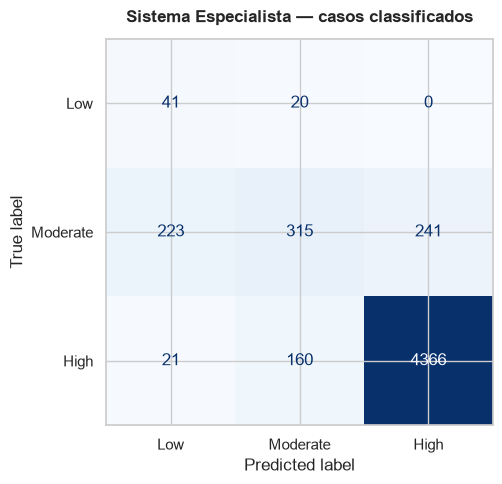

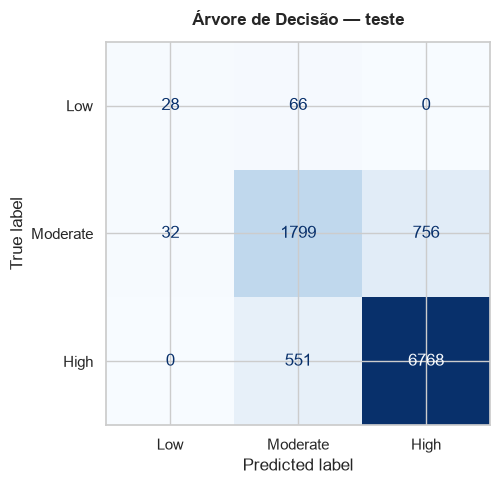

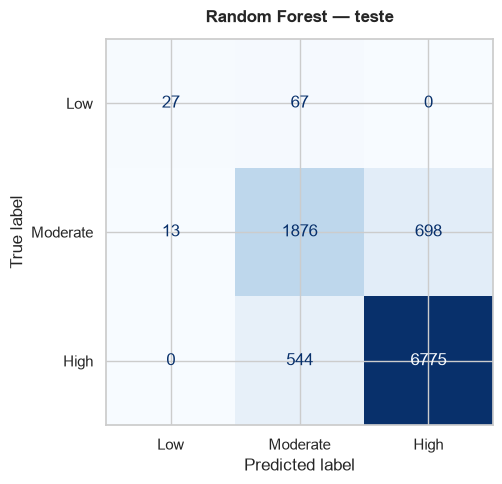

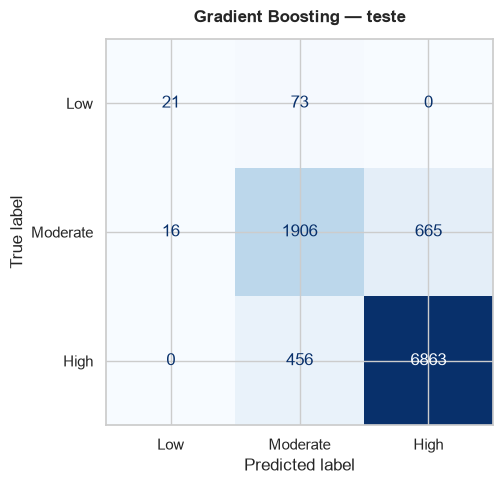

In [5]:
plotar_matriz_confusao(
    y_test_c[mascara_teste],
    resultado_c_teste.loc[mascara_teste, "conclusao"],
    classes=CLASSES,
    titulo="Sistema Especialista — casos classificados",
    arquivo_saida=FIGURES_DIR / "matriz_confusao_especialista.png",
)
plt.show()

nomes_arquivo_confusao = {
    "Árvore de Decisão": "matriz_confusao_arvore",
    "Random Forest": "matriz_confusao_random_forest",
    "Gradient Boosting": "matriz_confusao_gradient_boosting",
}

for nome, modelo in modelos_c.items():
    plotar_matriz_confusao(
        y_test_c,
        modelo.predict(X_test_c),
        classes=CLASSES,
        titulo=f"{nome} — teste",
        arquivo_saida=FIGURES_DIR / f"{nomes_arquivo_confusao[nome]}.png",
    )
    plt.show()

A classe **Low** é o principal problema de todos os modelos: ela representa
menos de 1% do teste, e tanto a árvore quanto os ensembles quase nunca a
prevêem. A matriz de confusão do especialista mostra que ele acerta parte dos
casos *Low* que consegue classificar, mas deixa muitos sem resposta.

### 2.2 Curvas ROC e Precision-Recall

As curvas são calculadas para os modelos que produzem probabilidades, focando a
classe **High** (a de maior custo clínico). O especialista não entra no gráfico
principal porque suas saídas são rótulos, não probabilidades.

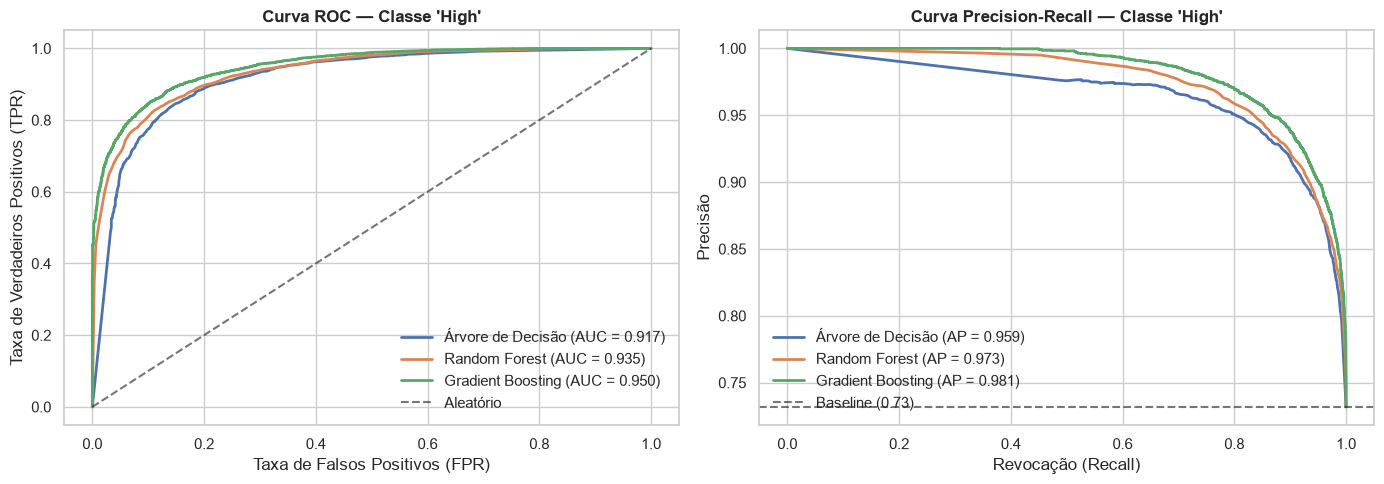

In [6]:
probabilidades = {
    nome: probabilidades_ordenadas(modelo, X_test_c)
    for nome, modelo in modelos_c.items()
}

plotar_curvas_roc_pr(
    y_test_c,
    probabilidades,
    classes=CLASSES,
    classe_foco="High",
    arquivo_saida=FIGURES_DIR / "curvas_roc_pr_comparativas.png",
)
plt.show()

### 2.3 Métricas por classe

A média macro dá o mesmo peso às três classes; a weighted pondera pelo suporte.
Como *Low* é rara, a diferença entre as duas é grande. Para um problema clínico,
a métrica principal deve refletir o custo dos erros: **F1 e recall da classe
High** são mais informativos que a accuracy, pois um falso negativo (classificar
um caso de risco alto como moderado/baixo) é mais grave que um falso positivo.

In [7]:
linhas_por_classe = []

def adicionar_por_classe(nome, y_true, y_pred):
    relatorio = classification_report(
        y_true, y_pred, labels=CLASSES, output_dict=True, zero_division=0
    )
    for classe in CLASSES:
        linhas_por_classe.append(
            {
                "Modelo": nome,
                "Classe": classe,
                "Precision": relatorio[classe]["precision"],
                "Recall": relatorio[classe]["recall"],
                "F1": relatorio[classe]["f1-score"],
                "Suporte": relatorio[classe]["support"],
            }
        )

adicionar_por_classe(
    "Sistema Especialista",
    y_test_c[mascara_teste],
    resultado_c_teste.loc[mascara_teste, "conclusao"],
)
for nome, modelo in modelos_c.items():
    adicionar_por_classe(nome, y_test_c, modelo.predict(X_test_c))

tabela_por_classe = pd.DataFrame(linhas_por_classe)
display(tabela_por_classe.round(4))
tabela_por_classe.to_csv(
    TABLES_DIR / "metricas_por_classe.csv", index=False, encoding="utf-8"
)

,Modelo,Classe,Precision,Recall,F1,Suporte
0,Sistema Especialista,Low,0.1439,0.6721,0.2370,61.0
1,Sistema Especialista,Moderate,0.6364,0.4044,0.4945,779.0
2,Sistema Especialista,High,0.9477,0.9602,0.9539,4547.0
3,Árvore de Decisão,Low,0.4667,0.2979,0.3636,94.0
4,Árvore de Decisão,Moderate,0.7446,0.6954,0.7192,2587.0
5,Árvore de Decisão,High,0.8995,0.9247,0.9119,7319.0
6,Random Forest,Low,0.6750,0.2872,0.4030,94.0
7,Random Forest,Moderate,0.7543,0.7252,0.7395,2587.0
8,Random Forest,High,0.9066,0.9257,0.9160,7319.0
9,Gradient Boosting,Low,0.5676,0.2234,0.3206,94.0


**Accuracy é enganosa?** Sim. Com 73% de *High*, um classificador que sempre
prevê *High* teria accuracy 0,73 e F1 macro próximo de 0,28. A accuracy do
especialista (0,877) é alta, mas ele só cobre metade dos casos. Por isso
reportamos F1 macro, F1/recall de *High* e cobertura em conjunto.

## 3. Métricas de regressão

In [8]:
pred_v1_treino = aplicar_sistema_especialista(
    X_train_r, REGRAS_REGRESSAO_V1
)["conclusao"].astype(float)
pred_v1_teste = aplicar_sistema_especialista(
    X_test_r, REGRAS_REGRESSAO_V1
)["conclusao"].astype(float)

pred_v2_treino = aplicar_sistema_especialista_pontuacao(
    X_train_r, REGRAS_REGRESSAO, PONTUACAO_BASE, LIMITES_PONTUACAO
)["conclusao"].to_numpy()
pred_v2_teste = aplicar_sistema_especialista_pontuacao(
    X_test_r, REGRAS_REGRESSAO, PONTUACAO_BASE, LIMITES_PONTUACAO
)["conclusao"].to_numpy()

previsoes_r = {
    "Especialista v1 (4 células)": (pred_v1_treino, pred_v1_teste),
    "Especialista v2 (19 faixas)": (pred_v2_treino, pred_v2_teste),
}
for nome, modelo in modelos_r.items():
    previsoes_r[nome] = (
        modelo.predict(X_train_r),
        modelo.predict(X_test_r),
    )

linhas_r = []
for nome, (pred_treino, pred_teste) in previsoes_r.items():
    m_treino = calcular_metricas_regressao(y_train_r, pred_treino)
    m_teste = calcular_metricas_regressao(y_test_r, pred_teste)
    linhas_r.append(
        {
            "Modelo": nome,
            "MAE Treino": m_treino["MAE"],
            "MAE Teste": m_teste["MAE"],
            "MSE Teste": m_teste["MSE"],
            "RMSE Teste": m_teste["RMSE"],
            "MAPE Teste (%)": m_teste["MAPE (%)"],
            "R2 Teste": m_teste["R2"],
            "MedAE Teste": m_teste["MedAE"],
        }
    )

tabela_r = pd.DataFrame(linhas_r).set_index("Modelo")
display(tabela_r.round(4))
tabela_r.to_csv(TABLES_DIR / "desempenho_regressao.csv", encoding="utf-8")

,MAE Treino,MAE Teste,MSE Teste,RMSE Teste,MAPE Teste (%),R2 Teste,MedAE Teste
Modelo,,,,,,,
Especialista v1 (4 células),11.2458,11.2721,194.0894,13.9316,17.1501,0.1964,9.6733
Especialista v2 (19 faixas),5.9902,5.9941,56.6337,7.5255,8.7747,0.7655,5.0000
Árvore de Decisão,5.8279,6.2824,62.0958,7.8801,9.2179,0.7429,5.2752
Random Forest,4.5915,6.1402,58.7201,7.6629,8.9851,0.7569,5.2245
Gradient Boosting,5.8817,5.9278,54.4626,7.3799,8.6523,0.7745,5.0677


**Leitura.** O especialista v2 (MAE 5,99; R² 0,766) supera a árvore ajustada
(MAE 6,28; R² 0,743) e fica entre Random Forest (MAE 6,14; R² 0,757) e Gradient
Boosting (MAE 5,93; R² 0,775). A v1 (MAE 11,27; R² 0,196) é claramente
insuficiente — evidência de que a representação por faixas aditivas foi a
mudança decisiva, não apenas um ajuste cosmético.

Em erro absoluto, o Gradient Boosting é o melhor. A diferença para o
especialista v2 é de apenas 0,07 no MAE, mas o custo computacional e a
complexidade são muito maiores (ver notebook 08).

### 3.1 Resíduos e valores reais versus previstos

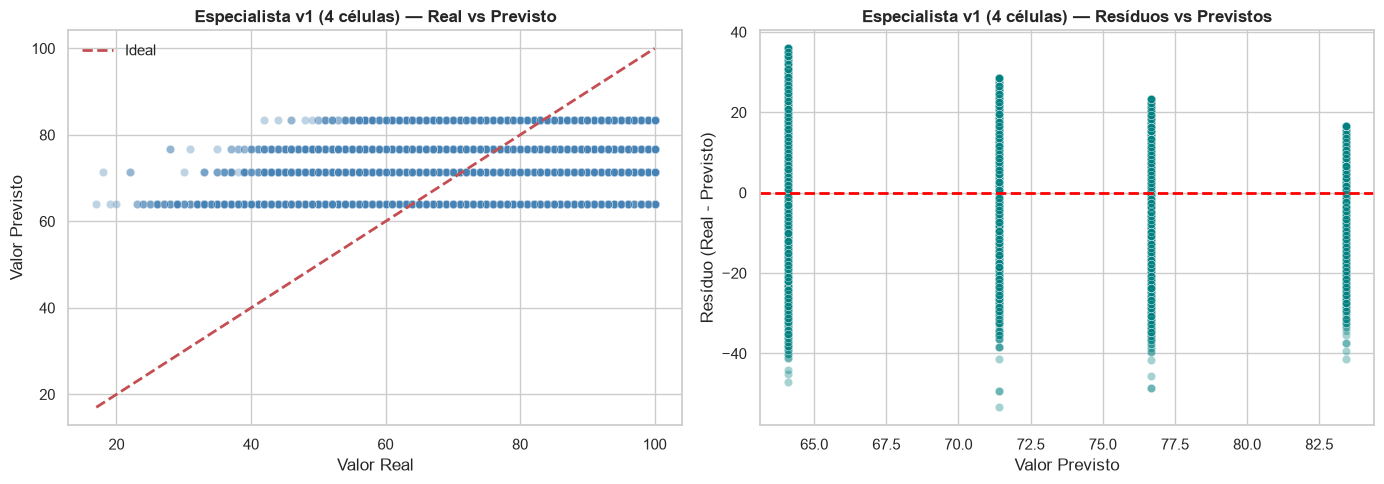

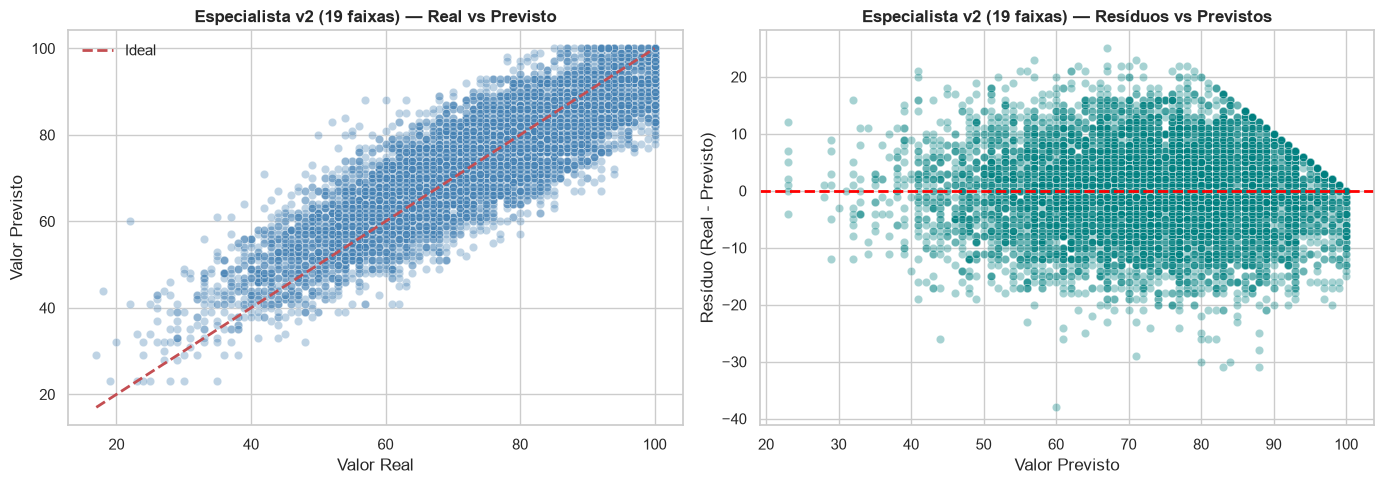

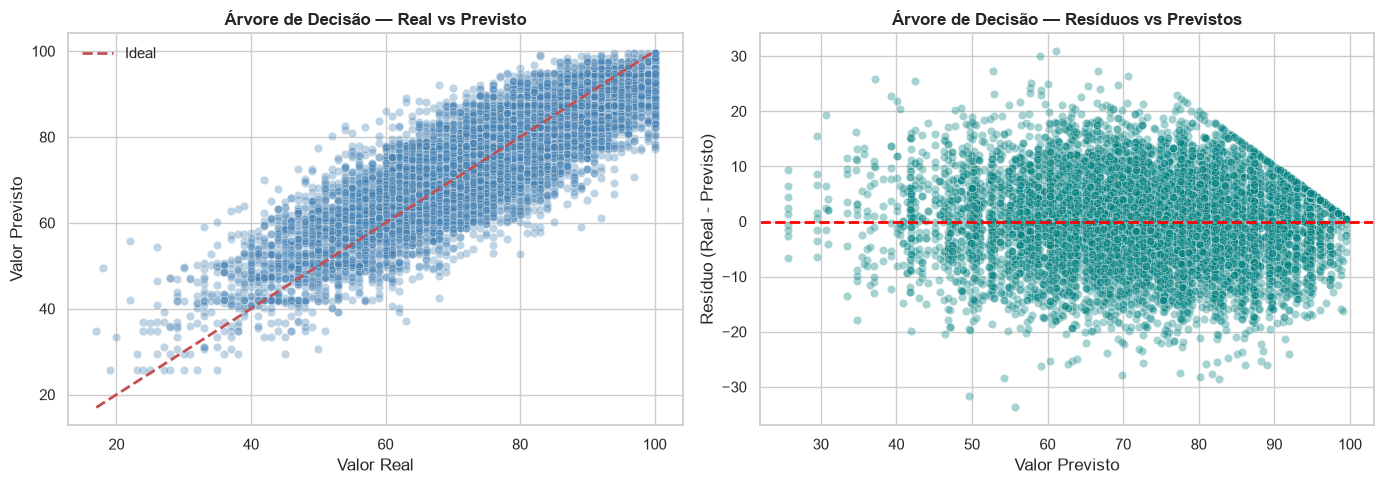

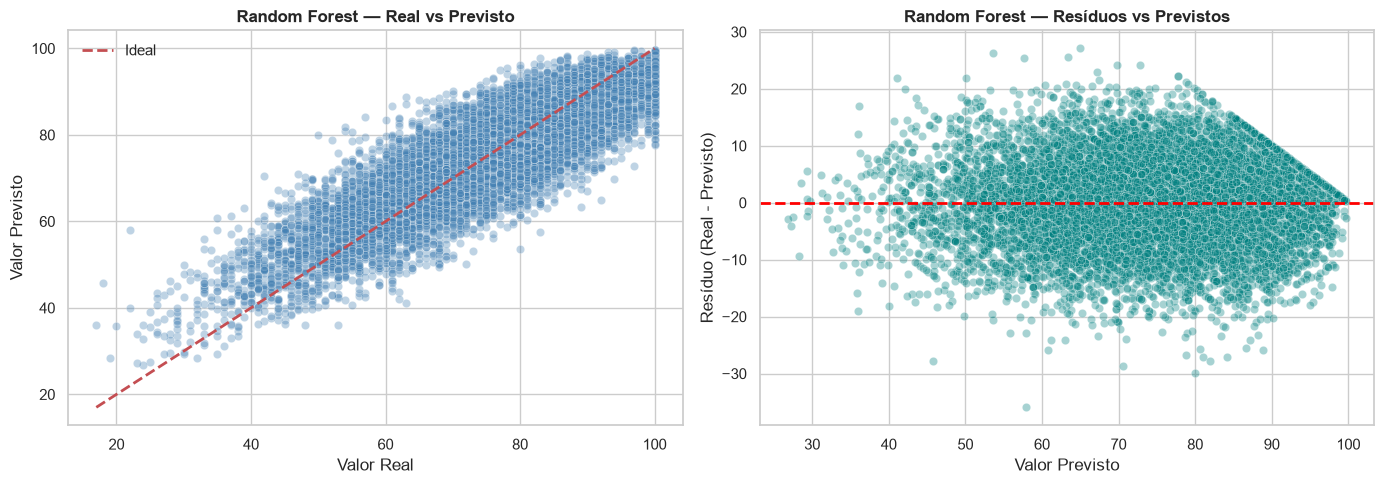

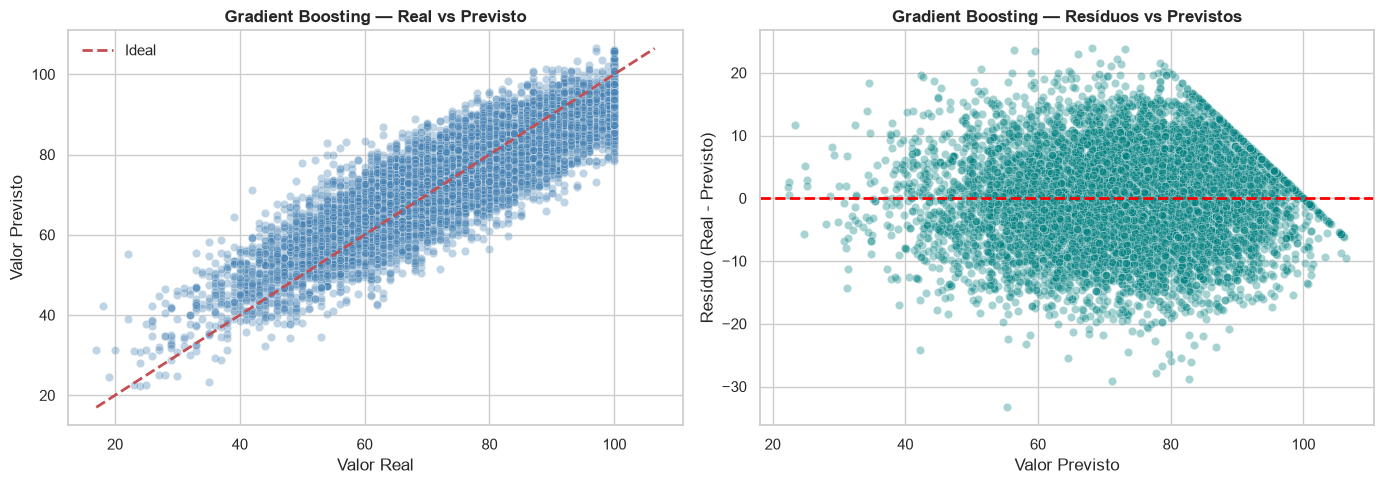

In [9]:
nomes_arquivo_residuo = {
    "Especialista v1 (4 células)": "residuos_especialista_v1",
    "Especialista v2 (19 faixas)": "residuos_especialista_v2",
    "Árvore de Decisão": "residuos_arvore",
    "Random Forest": "residuos_random_forest",
    "Gradient Boosting": "residuos_gradient_boosting",
}

for nome, (_, pred_teste) in previsoes_r.items():
    plotar_residuos(
        y_test_r,
        pred_teste,
        titulo=nome,
        arquivo_saida=FIGURES_DIR / f"{nomes_arquivo_residuo[nome]}.png",
    )
    plt.show()

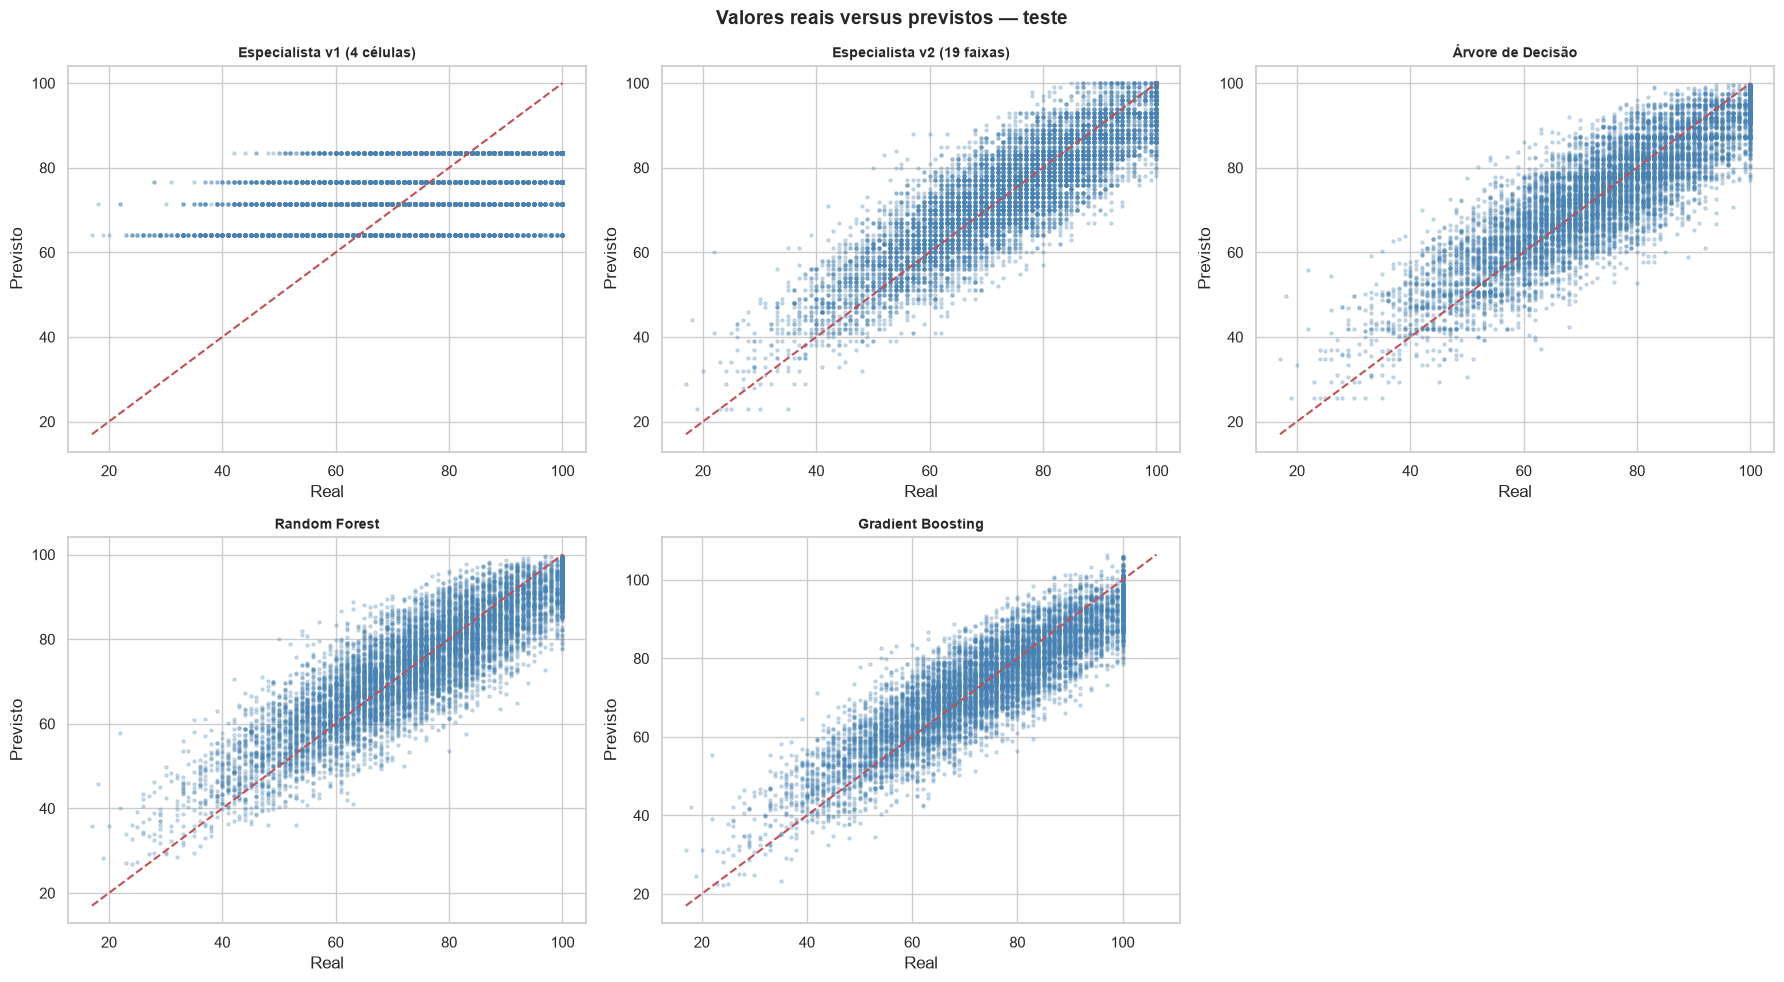

In [10]:
fig, eixos = plt.subplots(2, 3, figsize=(18, 10))
eixos = eixos.ravel()

for eixo, (nome, (_, pred_teste)) in zip(eixos, previsoes_r.items()):
    eixo.scatter(y_test_r, pred_teste, s=5, alpha=0.25, color="steelblue")
    limite = [min(y_test_r.min(), pred_teste.min()), max(y_test_r.max(), pred_teste.max())]
    eixo.plot(limite, limite, "r--", linewidth=1.5)
    eixo.set_title(nome, fontsize=10, fontweight="bold")
    eixo.set_xlabel("Real")
    eixo.set_ylabel("Previsto")

eixos[-1].axis("off")
fig.suptitle("Valores reais versus previstos — teste", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "residuos_comparativos.png", dpi=300, bbox_inches="tight")
plt.show()

O especialista v2 e o Gradient Boosting reproduzem a tendência central, mas
erram mais nos extremos (escores muito baixos ou muito altos), onde há menos
exemplos. A árvore mostra o padrão em degraus; a Random Forest suaviza, mas
ainda tem dispersão. O MAPE é seguro aqui porque o alvo mínimo é 13 (não há
divisão por zero), mas ele penaliza mais os escores baixos; por isso o MAE e o
RMSE são as métricas principais.

### 3.2 MAE versus RMSE

O RMSE penaliza mais os erros grandes (é a raiz do erro quadrático). Se o custo
de um erro grande for muito superior ao de vários erros pequenos, o RMSE é mais
adequado. Para comunicar o erro típico ao cliente, o MAE é mais intuitivo (está
na mesma unidade do escore).

## 4. Síntese

* **Classificação:** Random Forest tem o melhor F1 macro; Gradient Boosting tem
  a melhor accuracy e o melhor F1/recall de *High*. O especialista é competitivo
  em *High*, mas erra *Moderate* e deixa 46% do teste sem classificação.
* **Regressão:** Gradient Boosting tem o menor MAE; o especialista v2 fica muito
  próximo e supera árvore e Random Forest. A v1 é a pior alternativa.
* **Desbalanceamento:** accuracy isolada é enganosa; F1 macro, F1/recall de
  *High* e cobertura são as métricas de decisão.
* **Probabilidades:** apenas árvore e ensembles produzem probabilidades
  calibradas o suficiente para ROC/PR; o especialista é simbólico.